<a href="https://colab.research.google.com/github/jayakrishnan004/DSA_Assessment_ICTAK/blob/main/Assessment3_JayakrishnanKV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **1. Data understanding and exploratory analysis**

In [138]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, precision_score, recall_score, f1_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [139]:
df = pd.read_csv("/content/drive/MyDrive/DSA - ICTAK/Assessment/Assessment 3 - Supervised learning/bank_marketing_assessment_dataset.csv")

In [140]:
df.head()

,customer_age,job,marital_status,education,account_balance,housing_loan,personal_loan,contact_type,contact_month,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate,subscribed
0,69,retired,divorced,secondary,5467.0,no,no,unknown,nov,4,0,8,23029,no
1,21,admin,single,secondary,606.0,no,no,telephone,may,8,0,1,12000,no
2,27,technician,married,tertiary,-314.0,yes,no,cellular,nov,12,0,10,43597,no
3,53,management,single,secondary,1503.0,yes,yes,cellular,nov,6,0,10,24602,no
4,51,management,single,secondary,3037.0,no,no,unknown,jun,5,0,2,27127,no


In [141]:
df.shape

(600, 14)

In [142]:
df.columns

Index(['customer_age', 'job', 'marital_status', 'education', 'account_balance',
       'housing_loan', 'personal_loan', 'contact_type', 'contact_month',
       'campaign_contacts', 'previous_contacts', 'engagement_score',
       'annual_income_estimate', 'subscribed'],
      dtype='object')

In [143]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_age            600 non-null    int64  
 1   job                     600 non-null    object 
 2   marital_status          600 non-null    object 
 3   education               585 non-null    object 
 4   account_balance         588 non-null    float64
 5   housing_loan            600 non-null    object 
 6   personal_loan           600 non-null    object 
 7   contact_type            591 non-null    object 
 8   contact_month           600 non-null    object 
 9   campaign_contacts       600 non-null    int64  
 10  previous_contacts       600 non-null    int64  
 11  engagement_score        600 non-null    int64  
 12  annual_income_estimate  600 non-null    int64  
 13  subscribed              600 non-null    object 
dtypes: float64(1), int64(5), object(8)
memory 

In [144]:
df.dtypes

,0
customer_age,int64
job,object
marital_status,object
education,object
account_balance,float64
housing_loan,object
personal_loan,object
contact_type,object
contact_month,object
campaign_contacts,int64


In [145]:
df.describe()

,customer_age,account_balance,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate
count,600.000000,588.000000,600.000000,600.000000,600.000000,600.0000
mean,38.208333,1535.037415,5.566667,1.015000,4.451667,31805.3650
std,15.387426,2366.916896,2.020485,1.582914,2.938603,17264.0821
min,18.000000,-5418.000000,3.000000,0.000000,1.000000,12000.0000
25%,26.000000,-24.750000,4.000000,0.000000,1.000000,16112.5000
50%,34.000000,1589.500000,5.000000,0.000000,4.000000,29156.0000
75%,49.000000,3042.750000,7.000000,2.000000,7.000000,43444.0000
max,75.000000,9365.000000,13.000000,8.000000,10.000000,108930.0000


In [146]:
# Identify missing values.
df.isnull().sum()

,0
customer_age,0
job,0
marital_status,0
education,15
account_balance,12
housing_loan,0
personal_loan,0
contact_type,9
contact_month,0
campaign_contacts,0


In [147]:
# check for duplicate rows.
df.duplicated().sum()

np.int64(0)

Report the target-class distribution and at least two useful observations from the data. Use suitable visualisations.

In [148]:
df['subscribed'].value_counts()

,count
subscribed,
no,426
yes,174


In [149]:
# Percentage
df['subscribed'].value_counts(normalize = True) * 100

,proportion
subscribed,
no,71.0
yes,29.0


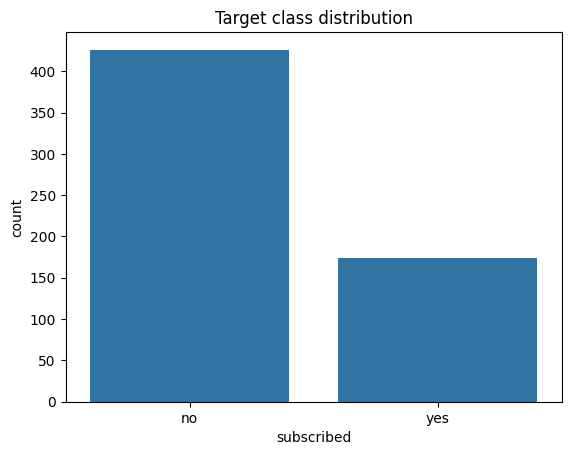

In [150]:
sns.countplot(data = df, x = 'subscribed')
plt.title("Target class distribution")
plt.show()

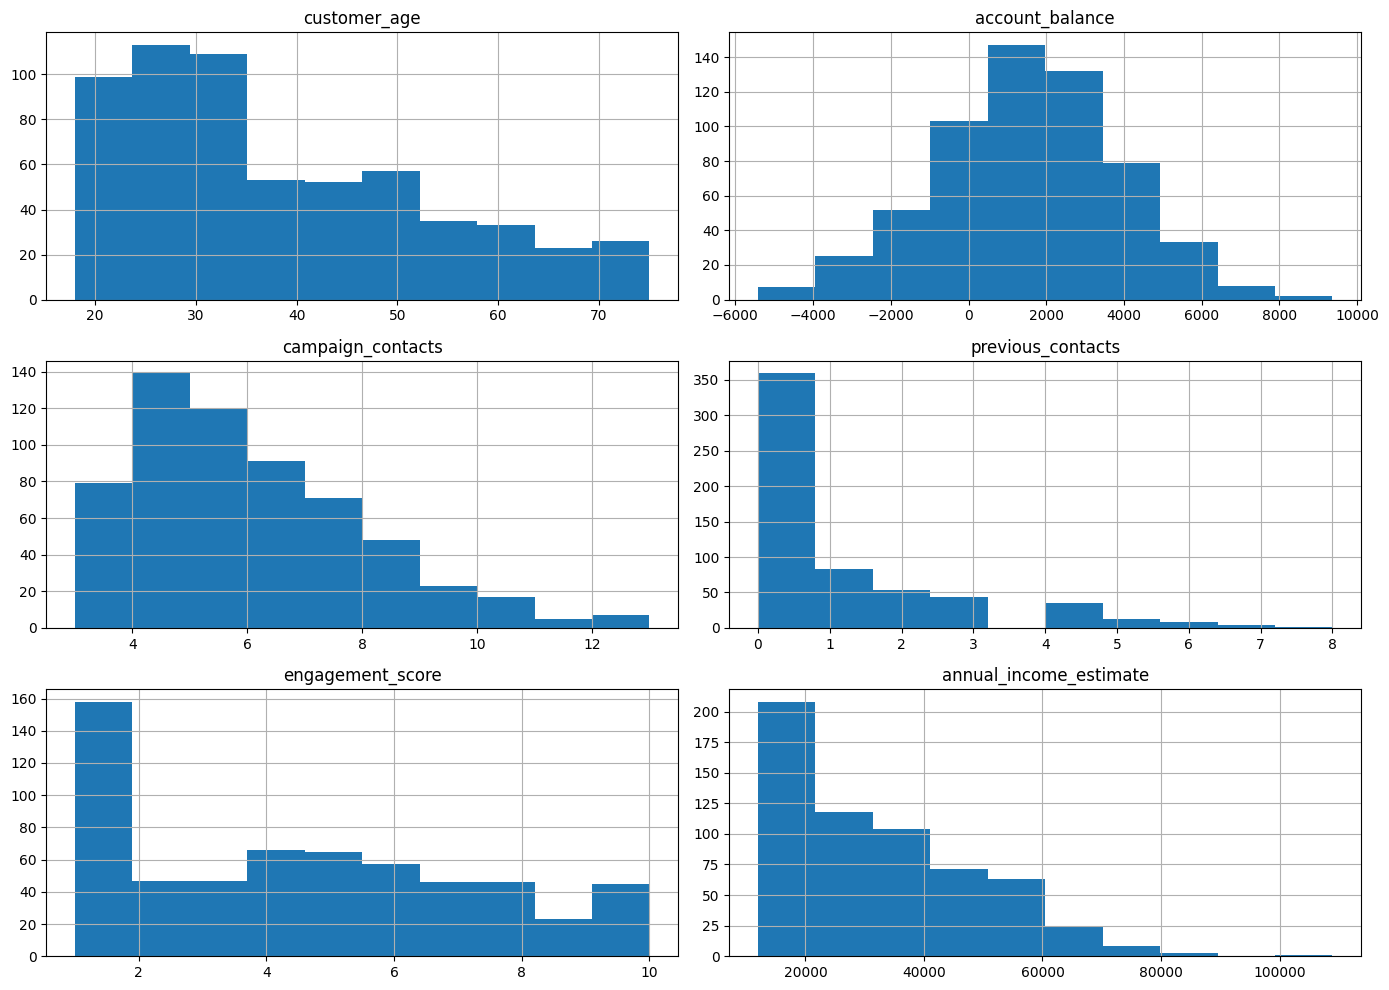

In [151]:
# Numerical feature distributions.
df.hist(figsize=(14, 10))
plt.tight_layout()
plt.show()

# **2. Data preparation and feature engineering**

In [152]:
# Separate the input features.
x = df.drop(columns = 'subscribed')
y = df['subscribed']

In [153]:
# Split the data into training and test sets using an 80:20 split and a fixed random_state. Use stratification.

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42, stratify =  y)

In [154]:
print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)


Training shape: (480, 13)
Testing shape: (120, 13)


Handle missing values appropriately. Encode categorical features and scale numerical features where appropriate.

In [155]:
# numerical columns.
num_cols = list(x.select_dtypes(include = np.number).columns)
print("Numerical columns :",num_cols)

# Categorical columns.
cat_cols = list(x.select_dtypes(include = object).columns)
print("Categorical columns :", list(cat_cols))


Numerical columns : ['customer_age', 'account_balance', 'campaign_contacts', 'previous_contacts', 'engagement_score', 'annual_income_estimate']
Categorical columns : ['job', 'marital_status', 'education', 'housing_loan', 'personal_loan', 'contact_type', 'contact_month']


In [156]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

# **3. Model building**

In [157]:
# Build a Logistic Regression classification model.
lr = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter = 1000,
        random_state = 42
    ))
])

lr.fit(x_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['customer_age',
                                                   'account_balance',
                                                   'campaign_contacts',
                                                   'previous_contacts',
                                                   'engagement_score',
                                                   'annual_income_estimate']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['job', 'marital_status',
                                                   'education', 'housing_loan',
                                                   'personal_loan',
                                                   'contact_type',
                                                   'contact_month'])])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [158]:
# Make predictions using Logistic regression model.
LR_pred = lr.predict(x_test)
print(LR_pred)

['no' 'yes' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no'
 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no'
 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'yes'
 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no'
 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'yes' 'no' 'yes'
 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'yes'
 'yes' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'no'
 'no' 'no' 'no' 'yes' 'yes' 'no' 'no' 'yes' 'no' 'no' 'no' 'yes' 'no'
 'yes' 'no' 'yes' 'no' 'yes' 'no' 'no' 'no' 'no']


In [159]:
# Build random forest model.
rf = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced'
    ))
])

rf.fit(x_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['customer_age',
                                                   'account_balance',
                                                   'campaign_contacts',
                                                   'previous_contacts',
                                                   'engagement_score',
                                                   'annual_income_estimate']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['job', 'marital_status',
                                                   'education', 'housing_loan',
                                                   'personal_loan',
                                                   'contact_type',
                                                   'contact_month'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=200, random_state=42))])

In [160]:
# Make predictions using Random forest model.
RF_pred = rf.predict(x_test)
print(RF_pred)

['no' 'yes' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no'
 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'yes' 'no'
 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'yes'
 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no'
 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'yes' 'no' 'yes'
 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'yes'
 'yes' 'yes' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no'
 'no' 'no' 'no' 'yes' 'yes' 'no' 'no' 'yes' 'no' 'no' 'no' 'yes' 'no'
 'yes' 'no' 'no' 'no' 'yes' 'no' 'no' 'no' 'no']


# **4. Model evaluation and comparison**

In [161]:
print("LOGISTIC REGRESSION")

print("Accuracy:", accuracy_score(y_test, LR_pred))
print("Precision:", precision_score(y_test, LR_pred, pos_label='yes'))
print("Recall:", recall_score(y_test, LR_pred, pos_label='yes'))
print("F1 Score:", f1_score(y_test, LR_pred, pos_label='yes'))

LOGISTIC REGRESSION
Accuracy: 0.85
Precision: 0.8695652173913043
Recall: 0.5714285714285714
F1 Score: 0.6896551724137931


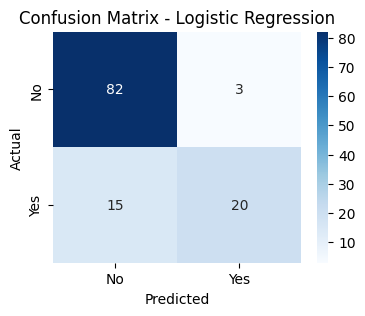

In [162]:
# Compute the confusion matrix for Logistic Regression
lr_cm = confusion_matrix(y_test, LR_pred, labels=['no', 'yes'])

# Visualize the confusion matrix
plt.figure(figsize=(4, 3))
sns.heatmap(lr_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No', 'Yes'],
            yticklabels=['No', 'Yes'])
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [163]:
print("RANDOM FOREST")

print("Accuracy:", accuracy_score(y_test, RF_pred))
print("Precision:", precision_score(y_test, RF_pred, pos_label='yes'))
print("Recall:", recall_score(y_test, RF_pred, pos_label='yes'))
print("F1 Score:", f1_score(y_test, RF_pred, pos_label='yes'))

RANDOM FOREST
Accuracy: 0.85
Precision: 0.8695652173913043
Recall: 0.5714285714285714
F1 Score: 0.6896551724137931


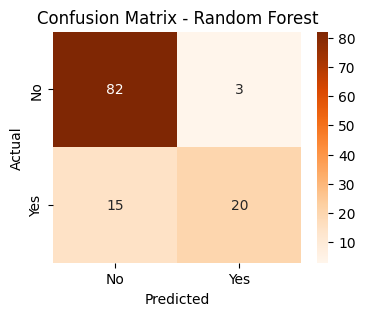

In [164]:
# Compute the confusion matrix for Random Forest
rf_cm = confusion_matrix(y_test, RF_pred, labels=['no', 'yes'])

# Visualize the confusion matrix
plt.figure(figsize=(4, 3))
sns.heatmap(rf_cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['No', 'Yes'],
            yticklabels=['No', 'Yes'])
plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

If Logistic Regression has higher recall, it identifies more potential subscribers.



If Random Forest has higher recall, it may be more suitable for identifying potential subscribers.



If one model has better F1-score, it offers a better balance between precision and recall.

### Model Interpretation and Limitations

**Key Observations on Feature Influence:**
* The feature importance bar plot above shows how much each feature contributes to reducing impurity across all decision trees in the Random Forest.
* Numeric features like engagement_score, account_balance, and annual_income_estimate typically rank highly as strong discriminators of subscription behavior.

**Limitations of the Feature Importance Interpretation:**
1. **Direction of Influence**: This method only tells us *which* features are influential, not *how* they affect the outcome (whether they increase or decrease the likelihood of subscription).
2. **Correlation Bias**: If two features are highly correlated, Random Forest splits the importance between them, which can make both appear less important than they actually are.
3. **Cardinality Bias**: Tree-based impurity importances tend to favor continuous (numerical) variables or categorical variables with many unique categories (high cardinality) over low-cardinality binary features.